# Stochastic MDS and NMDS

# ... aka *Non-metric multidimensional scaling at scale*

In [ ]:
# conda create -n nmds -c conda-forge python numpy scipy scikit-learn opentsne umap-learn notebook matplotlib ipywidgets pandas
# conda activate nmds
# pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cpu

In [1]:
import numpy as np
import pylab as plt
import time

from sklearn.metrics import pairwise_distances
from sklearn.datasets import load_digits, make_blobs
from sklearn.manifold import ClassicalMDS, MDS
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression

from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from openTSNE import TSNE
from umap import UMAP

import torch

# Print versions

import openTSNE, umap, sklearn
print("openTSNE", openTSNE.__version__)
print("UMAP", umap.__version__)
print("sklearn", sklearn.__version__)

# Load figure style file

plt.style.use('mpl_style.txt')

openTSNE 1.0.4
UMAP 0.5.11
sklearn 1.8.0


## Functions

In [2]:
def stochasticMDS(
    X,
    n_components=2,
    precomputed_distances=False,
    non_metric=False,
    verbose=True,
    n_epochs="auto",
    batch_size="auto",
    print_every_epoch="auto",
    lr=0.02,
    start_nonmetric_from_epoch=0,
    isotonic_fit_how_often=0,
    init_scale=0.5,
    init=None,
    seed=42,               # NEW
    # normalize_dist=True,   # EXPERIMENTAL
    # use_stress1_loss=False, # EXPERIMENTAL
    # normalize_dist_first_batch_only=True, # EXPERIMENTAL
):

    sample_size = X.shape[0]

    if batch_size == "auto":
        if sample_size <= 5000:
            batch_size = 100
        else:
            batch_size = 1000
            
    if n_epochs == "auto":
        if sample_size <= 50_000:
            n_epochs = 200
        else:
            n_epochs = 20

    if print_every_epoch == "auto":
        if n_epochs > 20:
            print_every_epoch = 10
        else:
            print_every_epoch = 1

    if init is not None:        
        Z = init
    else:
        if precomputed_distances:
            Z = ClassicalMDS(n_components=n_components).fit_transform(X)
        else:
            Z = PCA(n_components=n_components).fit_transform(X)
        Z /= np.std(Z[:, 0])
        Z *= init_scale

    torch.manual_seed(seed)  # FIXME IN MANUSCRIPT
    
    model = torch.nn.Embedding(sample_size, n_components).from_pretrained(
        torch.tensor(Z.astype(np.float32)), freeze=False
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

    if non_metric:
        ir = IsotonicRegression(out_of_bounds="clip")

    epochs_stress1 = np.zeros(n_epochs)
    
    for epoch in range(n_epochs):
        shuffle = torch.randperm(sample_size)

        epoch_stress1 = 0
        t_start = time.time()

        for batch in range(sample_size // batch_size):
            ind = shuffle[batch * batch_size : (batch + 1) * batch_size]

            if precomputed_distances:
                dists = X[ind.numpy(), :][:, ind.numpy()]     # FIXME IN MANUSCRIPT
            else:
                dists = cdist(X[ind.numpy()], X[ind.numpy()])
            
            # if normalize_dist: # EXPERIMENTAL
            #     if normalize_dist_first_batch_only:
            #         if batch == 0:
            #             dists_scaling = dists.mean()
            #         dists /= dists_scaling
            #     else:
            #         dists /= dists.mean()

            optimizer.zero_grad()
            model_dists = torch.squeeze(
                torch.cdist(model(ind)[None, :, :], model(ind)[None, :, :])
            )

            if non_metric:
                if epoch >= start_nonmetric_from_epoch:
                    if (
                        (isotonic_fit_how_often == 0 and batch == 0) or
                        (isotonic_fit_how_often > 0 and batch % isotonic_fit_how_often == 0) or
                        (isotonic_fit_how_often < 0 and batch == 0 and epoch % -isotonic_fit_how_often == 0)
                    ):
                        ir.fit(dists.ravel(), model_dists.detach().numpy().ravel())
                    dists = ir.transform(dists.ravel()).reshape(dists.shape)
                    
            # if normalize_dist: # EXPERIMENTAL
                # if normalize_dist_first_batch_only:
            if batch == 0:
                 # same normalization as in sklearn (NEW!!)
                dists_scaling = np.sqrt(np.sum(dists ** 2) / (batch_size ** 2 - batch_size))
                # dists_scaling = dists.mean()
            dists /= dists_scaling
                # else:
                    # dists /= dists.mean()

            dists = torch.tensor(dists.astype(np.float32))

            # Loss function = Stress-1
            raw_stress = torch.mean((model_dists - dists)**2)
            
            # EXPERIMENTAL
            # stress1 = raw_stress / torch.mean(model_dists ** 2)
            # stress1 = torch.sqrt(stress1)
            # stress1.backward()

            raw_stress.backward()
            optimizer.step()

            # This is sqrt of "normalized stress" (Borg & Groenen)
            # After convergence it is equal to the optimal stress 1

            # TO-DO: check n(n-1) vs n**2 everywhere here
            stress1 = np.sqrt(raw_stress.item() / np.mean(dists.detach().numpy() ** 2))
            
            epoch_stress1 += stress1.item()

        scheduler.step()
        epoch_stress1 /= (sample_size // batch_size)
        t_end = time.time()

        epochs_stress1[epoch] = epoch_stress1
        if verbose and (epoch + 1) % print_every_epoch == 0:
            print(f"Epoch {epoch + 1:3}, stress-1 {epoch_stress1:.3f}, time {t_end - t_start:.1f} s")

    Z = model.weight.detach().numpy()
    return Z, epochs_stress1

In [3]:
# Compute Pearson and Spearman correlations between pairwise distances
# in high-dim space (X) and in a set of embeddings (Zs)

def dist_corrs(X, Zs, subset_size=5000, triplet_reps=10, seed=42, precomputed=False):
    rps = []
    rss = []
    sigmadists = []
    tripletaccs = []

    if subset_size > X.shape[0]:
        subset_size = X.shape[0]

    rng = np.random.default_rng(seed=seed)
    if subset_size < X.shape[0]:
        ind = rng.choice(
            X.shape[0],
            size=subset_size,
            replace=False
        )
    else:
        ind = np.arange(X.shape[0])

    if precomputed:
        d1 = X[ind, :][:, ind]
    else:
        d1 = pairwise_distances(X[ind, :])

    offdiag = np.triu_indices(subset_size, k=1)
    
    for Z in Zs:
        d2 = pairwise_distances(Z[ind, :])
        r = np.corrcoef(d1[offdiag], d2[offdiag])[0, 1]
        rps.append(r)
        r = spearmanr(d1[offdiag], d2[offdiag]).correlation
        rss.append(r)

        # Sigma-distortion
        rho = d2[offdiag] / d1[offdiag]
        s = np.var(rho / np.mean(rho))
        sigmadists.append(s)

        # Triplets
        triplet_accuracy = 0
        for rep in range(triplet_reps):
            for sample in range(d1.shape[0]):
                sorted_inds = np.argsort(d1[sample])
                close = sorted_inds[1:d1.shape[0] // 2]
                close = close[rng.choice(len(close))]
                far = sorted_inds[d1.shape[0] // 2 :]
                far = far[rng.choice(len(far))]
                triplet_accuracy += d2[sample, far] > d2[sample, close]
        triplet_accuracy /= (triplet_reps * d1.shape[0])
        tripletaccs.append(triplet_accuracy)

    return np.array(rps), np.array(rss), np.array(sigmadists), np.array(tripletaccs)

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import warnings

def classif_eval(y, Zs, seed=42):
    knn_acc = []
    lin_acc = []
    
    for Z in Zs:
        Xtrain, Xtest, ytrain, ytest = train_test_split(Z, y, random_state=seed, test_size=0.1)
        
        acc = KNeighborsClassifier(n_neighbors=10).fit(Xtrain, ytrain).score(Xtest, ytest)
        knn_acc.append(acc)

        # Ignoring possible convergence warning
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            acc = LogisticRegression(C=np.inf, random_state=seed).fit(Xtrain, ytrain).score(Xtest, ytest)
        lin_acc.append(acc)

    return np.array(knn_acc), np.array(lin_acc)

In [19]:
def stress1(X, Z, precomputed=False, non_metric=False, normalize_dist=False, adjust=False):
    d1 = X if precomputed else pairwise_distances(X)
    d2 = pairwise_distances(Z)
    
    d1 = d1.flatten()
    d2 = d2.flatten()

    if non_metric:
        ir = IsotonicRegression(out_of_bounds="clip")
        d1 = ir.fit_transform(d1, d2).flatten()

    # if normalize_dist == "mean":
        # d1 = d1 / np.mean(d1)
    if normalize_dist == "mean_square_offdiag":
        d1 = d1 / np.sqrt(np.sum(d1 ** 2) / (len(X) ** 2 - len(X)))

    stress1 = np.sqrt(np.mean((d1 - d2) ** 2) / np.mean(d2 ** 2))

    # print(stress1)

    # THE FOLLOWING TWO ARE THE SAME AT THE MINIMUM OF RAW STRESS!
    print("stress1", stress1)
    print("adjusted stress1", np.sqrt(stress1 ** 2 / (1 + stress1 ** 2)))
    print("sqrt of normalized stress", np.sqrt(np.mean((d1 - d2) ** 2) / np.mean(d1 ** 2)))
    print("mean transformed input dist", np.sum(d1**2) / (len(X) ** 2 - len(X)))
    print("")
    
    # Okay I am again confused by this: isn't denominator in the last line simply 1 for NMDS?
    # The answer: yes. So sqrt(raw stress) is the same as adjusted stress1 :)

    if adjust:
        stress1 = np.sqrt(stress1 ** 2 / (1 + stress1 ** 2))
    
    return stress1

In [20]:
# Verify that my stress1 function agrees with sklearn

X, y = make_blobs(n_samples=100, random_state=42)
X = np.concatenate(
    (X, np.random.default_rng(seed=42).normal(size=(X.shape[0], 1_000))),
    axis=1
)

mmds = MDS(normalized_stress=True, n_init=1, init="classical_mds")
Z2 = mmds.fit_transform(X)
assert(np.isclose(stress1(X, Z2, non_metric=False), mmds.stress_))

nmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", metric_mds=False)
Z3 = nmds.fit_transform(X)
assert(np.isclose(stress1(X, Z3, non_metric=True, normalize_dist="mean_square_offdiag"), nmds.stress_))

stress1 0.4280623257586641
adjusted stress1 0.39352386123615596
sqrt of normalized stress 0.39352378007583094
mean transformed input dist 2144.688952243264

stress1 0.23924045315285558
adjusted stress1 0.2326744232421232
sqrt of normalized stress 0.2326743700187138
mean transformed input dist 1.0



## Noisy blobs

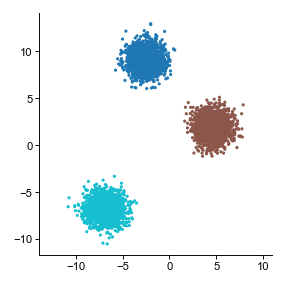

In [296]:
# Generate data

X, y = make_blobs(n_samples=5_000, random_state=42)#, centers=10, n_features=5) # was: 5_000
X = np.concatenate(
    (X, np.random.default_rng(seed=42).normal(size=(X.shape[0], 1_000))), # was: 1_000
    axis=1
)

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(X[:, 0], X[:, 1], s=2, c=y, cmap='tab10');

In [25]:
# Compute embeddings using sklearn

cmds = ClassicalMDS()
%time Z1 = cmds.fit_transform(X)
print("")

mmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", verbose=1)
%time Z2 = mmds.fit_transform(X)
stress1_rescaled = np.sqrt(mmds.stress_**2 / (1 + mmds.stress_**2))
print(f"MMDS stress-1: {stress1_rescaled:.3f}\n")

nmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", metric_mds=False, verbose=1)
%time Z3 = nmds.fit_transform(X)
print(f"NMDS stress-1: {nmds.stress_:.3f}")

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z1, Z2, Z3])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z1, Z2, Z3])
print("kNN acc:", knn)
print("lin acc:", lin)

CPU times: user 2min 44s, sys: 680 ms, total: 2min 44s
Wall time: 23 s

Convergence criterion reached (iteration 130).
CPU times: user 6min 57s, sys: 1min 23s, total: 8min 21s
Wall time: 1min 56s
MMDS stress-1: 0.402

Convergence criterion reached (iteration 61).
CPU times: user 14min 29s, sys: 1min 14s, total: 15min 43s
Wall time: 10min 52s
NMDS stress-1: 0.252

Pearson: [0.76061726 0.66522238 0.84476691]
Spearman: [0.77790248 0.67151023 0.85086528]
Sigma-distortion: [0.37908473 0.19922052 0.26847264]
Triplet: [0.8904 0.826  0.914 ]
kNN acc: [1. 1. 1.]
lin acc: [1. 1. 1.]


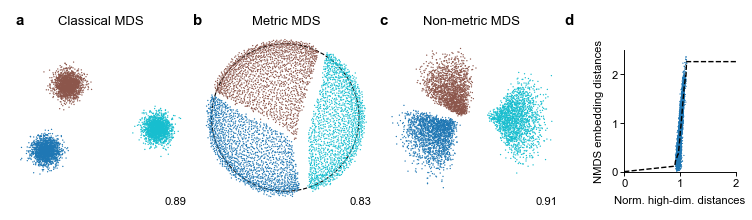

In [26]:
# Make a figure

titles = ["Classical MDS", "Metric MDS", "Non-metric MDS"]

fig, axs = plt.subplots(ncols=4, figsize=(5.5, 1.5), layout="constrained")

for i, Z in enumerate([Z1, Z2, Z3]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=2, ec="none", c=y, cmap='tab10', rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])
    # axs[i].text(.95, .12, f"P: {rps[i]:.2f}", ha="right", transform=axs[i].transAxes)
    axs[i].text(.99, .01, f"{tas[i]:.2f}", ha="right", transform=axs[i].transAxes)

    if i == 1:
        dists = pairwise_distances(X)
        mean_dist = np.mean(dists[dists > 0])
        c = plt.Circle((0, 0), mean_dist * np.pi / 4, facecolor="none", edgecolor="k", linestyle='--', lw=.6, zorder=0)
        axs[i].add_patch(c)

# NMDS Shepard diagram

axs[3].set_visible(False)
axs[3] = plt.axes([.83, .2, .15, .6])

ind = np.random.default_rng(seed=42).choice(X.shape[0], size=100, replace=False)  # was: 500
d1 = pairwise_distances(X[ind, :])
d2 = pairwise_distances(Z[ind, :])
d1 /= d1.mean()

ir = IsotonicRegression(out_of_bounds="clip")
ir.fit(d1.ravel(), d2.ravel())

axs[3].scatter(d1.flatten(), d2.flatten(), s=1, ec='none', rasterized=True)
axs[3].set_xlabel("Norm. high-dim. distances")
axs[3].set_ylabel("NMDS embedding distances")

xgrid = np.arange(0, 2.5, .01)
yhat = ir.transform(xgrid.reshape(-1, 1))
axs[3].plot(xgrid, yhat, 'k--')
axs[3].set_xlim([0, 2])
axs[3].set_ylim([0, 2.5])
axs[3].set_yticks([0, 1, 2])
axs[3].spines[["right", "top"]].set_visible(False)

fig.text(.01, .93, "a", fontweight="bold", fontsize=8)
fig.text(.25, .93, "b", fontweight="bold", fontsize=8)
fig.text(.50, .93, "c", fontweight="bold", fontsize=8)
fig.text(.75, .93, "d", fontweight="bold", fontsize=8)

fig.savefig("figures/blobs.png", dpi=300)
fig.savefig("figures/blobs.pdf", dpi=300)

CPU times: user 48.5 s, sys: 31.7 ms, total: 48.5 s
Wall time: 46.6 s

CPU times: user 24.3 s, sys: 2.18 s, total: 26.4 s
Wall time: 4.69 s

Pearson: [0.67125895 0.61936099]
Spearman: [0.65985879 0.6735413 ]
Sigma-distortion: [0.41740237 0.60751364]
Triplet: [0.8402 0.8392]
kNN acc: [1. 1.]
lin acc: [1. 1.]


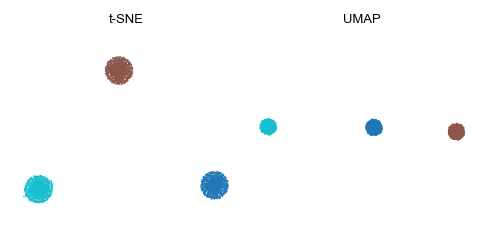

In [17]:
# Compute tSNE and UMAP

%time Z_tsne = TSNE().fit(X)
print("")
%time Z_umap = UMAP().fit_transform(X)

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z_tsne, Z_umap])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z_tsne, Z_umap])
print("kNN acc:", knn)
print("lin acc:", lin)

# Plot

fig, axs = plt.subplots(ncols=2, figsize=(3.5, 1.7), layout="constrained")
titles = ["t-SNE", "UMAP"]

for i, Z in enumerate([Z_tsne, Z_umap]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=2, ec="none", c=y, cmap='tab10', rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])

Epoch  10, stress-1 0.413, time 0.2 s
Epoch  20, stress-1 0.410, time 0.2 s
Epoch  30, stress-1 0.421, time 0.2 s
Epoch  40, stress-1 0.413, time 0.2 s
Epoch  50, stress-1 0.410, time 0.2 s
Epoch  60, stress-1 0.415, time 0.2 s
Epoch  70, stress-1 0.408, time 0.2 s
Epoch  80, stress-1 0.408, time 0.2 s
Epoch  90, stress-1 0.406, time 0.2 s
Epoch 100, stress-1 0.405, time 0.3 s
Epoch 110, stress-1 0.406, time 0.3 s
Epoch 120, stress-1 0.404, time 0.4 s
Epoch 130, stress-1 0.404, time 0.3 s
Epoch 140, stress-1 0.404, time 0.3 s
Epoch 150, stress-1 0.404, time 0.3 s
Epoch 160, stress-1 0.404, time 0.3 s
Epoch 170, stress-1 0.404, time 0.3 s
Epoch 180, stress-1 0.403, time 0.3 s
Epoch 190, stress-1 0.404, time 0.3 s
Epoch 200, stress-1 0.403, time 0.3 s
CPU times: user 3min 20s, sys: 85.8 ms, total: 3min 20s
Wall time: 50 s


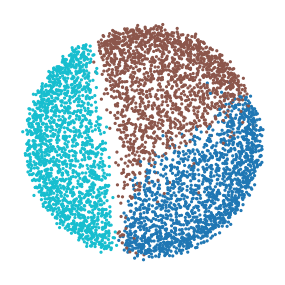

In [299]:
# Compute embeddings using SGD

%time Z, loss = stochasticMDS(X) # loss = 0.402

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=2, c=y, cmap='tab10')
plt.axis("off");

In [301]:
# Compute Stress-1 without batches:

stress1(X, Z, non_metric=False, normalize_dist="mean_square_offdiag", adjust=True)

np.float64(0.40308801919581216)

Epoch  10, stress-1 0.263, time 0.2 s
Epoch  20, stress-1 0.258, time 0.2 s
Epoch  30, stress-1 0.274, time 0.3 s
Epoch  40, stress-1 0.256, time 0.3 s
Epoch  50, stress-1 0.266, time 0.3 s
Epoch  60, stress-1 0.250, time 0.3 s
Epoch  70, stress-1 0.253, time 0.3 s
Epoch  80, stress-1 0.356, time 0.3 s
Epoch  90, stress-1 0.250, time 0.4 s
Epoch 100, stress-1 0.251, time 0.3 s
Epoch 110, stress-1 0.249, time 0.3 s
Epoch 120, stress-1 0.254, time 0.3 s
Epoch 130, stress-1 0.248, time 0.4 s
Epoch 140, stress-1 0.248, time 0.3 s
Epoch 150, stress-1 0.247, time 0.4 s
Epoch 160, stress-1 0.246, time 0.4 s
Epoch 170, stress-1 0.246, time 0.4 s
Epoch 180, stress-1 0.249, time 0.4 s
Epoch 190, stress-1 0.247, time 0.4 s
Epoch 200, stress-1 0.246, time 0.4 s
CPU times: user 4min 26s, sys: 160 ms, total: 4min 26s
Wall time: 1min 6s


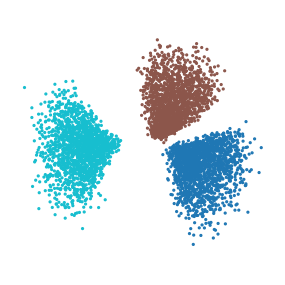

In [302]:
%time Z, loss = stochasticMDS(X, non_metric=True) # loss = 0.247

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=2, c=y, cmap='tab10')
plt.axis("off");

In [303]:
# Compute Stress-1 without batches:

stress1(X, Z, non_metric=True, normalize_dist="mean_square_offdiag", adjust=True)

np.float64(0.24336696232205063)

In [145]:
reps = 5
losses = np.zeros(reps)
evals = np.zeros((reps, 3))

for rep in range(reps):
    Z, loss = stochasticMDS(X, normalize_dist_first_batch_only=True, seed=rep)
    losses[rep] = loss

    a, b, _, c = dist_corrs(X, [Z], seed=rep)
    evals[rep] = (a[0], b[0], c[0])

print(np.std(losses))
print(np.std(evals, axis=0))

Epoch  10, loss 0.406, time 0.2 s
Epoch  20, loss 0.405, time 0.2 s
Epoch  30, loss 0.407, time 0.2 s
Epoch  40, loss 0.407, time 0.2 s
Epoch  50, loss 0.407, time 0.2 s
Epoch  60, loss 0.405, time 0.2 s
Epoch  70, loss 0.406, time 0.2 s
Epoch  80, loss 0.406, time 0.3 s
Epoch  90, loss 0.406, time 0.3 s
Epoch 100, loss 0.406, time 0.3 s
Epoch 110, loss 0.405, time 0.3 s
Epoch 120, loss 0.404, time 0.3 s
Epoch 130, loss 0.404, time 0.3 s
Epoch 140, loss 0.404, time 0.3 s
Epoch 150, loss 0.403, time 0.4 s
Epoch 160, loss 0.403, time 0.3 s
Epoch 170, loss 0.403, time 0.3 s
Epoch 180, loss 0.404, time 0.3 s
Epoch 190, loss 0.404, time 0.3 s
Epoch 200, loss 0.403, time 0.3 s
Epoch  10, loss 0.405, time 0.3 s
Epoch  20, loss 0.405, time 0.3 s
Epoch  30, loss 0.405, time 0.4 s
Epoch  40, loss 0.411, time 0.3 s
Epoch  50, loss 0.411, time 0.3 s
Epoch  60, loss 0.407, time 0.3 s
Epoch  70, loss 0.407, time 0.3 s
Epoch  80, loss 0.406, time 0.3 s
Epoch  90, loss 0.405, time 0.5 s
Epoch 100, los

In [146]:
print(evals)

[[0.61967615 0.62273845 0.8144    ]
 [0.60591635 0.60729749 0.808     ]
 [0.59964518 0.60152669 0.7938    ]
 [0.60527109 0.6098409  0.799     ]
 [0.62675663 0.63342894 0.8072    ]]


In [11]:
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=-100, print_every_epoch=200)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=-10, print_every_epoch=200)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=0, print_every_epoch=200)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=10, print_every_epoch=200)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=1, print_every_epoch=200)

Epoch 200, loss 0.249, time 0.4 s
CPU times: user 5min 6s, sys: 64 ms, total: 5min 6s
Wall time: 1min 16s
Epoch 200, loss 0.247, time 0.4 s
CPU times: user 5min 22s, sys: 64 ms, total: 5min 22s
Wall time: 1min 20s
Epoch 200, loss 0.249, time 0.4 s
CPU times: user 5min 24s, sys: 48 ms, total: 5min 24s
Wall time: 1min 20s
Epoch 200, loss 0.247, time 0.4 s
CPU times: user 5min 34s, sys: 68 ms, total: 5min 35s
Wall time: 1min 23s
Epoch 200, loss 0.245, time 0.5 s
CPU times: user 7min 55s, sys: 212 ms, total: 7min 56s
Wall time: 1min 58s


## 1000 genomes dataset

In [305]:
# Load data

# X = np.loadtxt('genomes-data/gt_sum_thinned.npy.gz')

# _, y = np.unique(
#     pd.read_csv("genomes-data/affy_samples.20141118.panel", delimiter="\t")["pop"].values,
#     return_inverse=True
# )

D = np.load("genomes-data/1000-genomes-D.npy")

from scipy.spatial.distance import squareform
D = squareform(D, force='tomatrix')

y = np.load("genomes-data/1000-genomes-labels.npy")

print(D.shape)

(3450, 3450)


In [19]:
# Compute embeddings using sklearn

cmds = ClassicalMDS(metric="precomputed")
%time Z1 = cmds.fit_transform(D)
print("")

mmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", metric="precomputed", verbose=1)
%time Z2 = mmds.fit_transform(D)
stress1_rescaled = np.sqrt(mmds.stress_**2 / (1 + mmds.stress_**2))
print(f"MMDS stress-1: {stress1_rescaled:.3f}\n")

nmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", metric_mds=False, metric="precomputed", verbose=1)
%time Z3 = nmds.fit_transform(D)
print(f"NMDS stress-1: {nmds.stress_:.3f}")

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(D, [Z1, Z2, Z3], precomputed=True)
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z1, Z2, Z3])
print("kNN acc:", knn)
print("lin acc:", lin)

CPU times: user 59.1 s, sys: 256 ms, total: 59.3 s
Wall time: 9.55 s

Convergence criterion reached (iteration 237).
CPU times: user 6min 33s, sys: 1min 10s, total: 7min 43s
Wall time: 1min 26s
MMDS stress-1: 0.406

Convergence criterion reached (iteration 60).
CPU times: user 5min 9s, sys: 23.9 s, total: 5min 32s
Wall time: 3min 17s
NMDS stress-1: 0.129

Pearson: [0.82359068 0.69285054 0.89869251]
Spearman: [0.84360566 0.70947313 0.96047676]
Sigma-distortion: [0.38426836 0.20463079 0.34428336]
Triplet: [0.913  0.8498 0.959 ]
kNN acc: [0.54782609 0.52173913 0.6173913 ]
lin acc: [0.48985507 0.45507246 0.53623188]


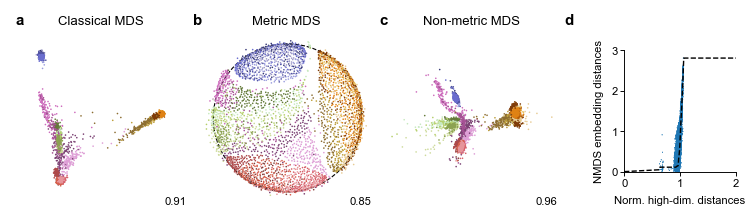

In [22]:
# Make a figure

titles = ["Classical MDS", "Metric MDS", "Non-metric MDS"]

fig, axs = plt.subplots(ncols=4, figsize=(5.5, 1.5), layout="constrained")

for i, Z in enumerate([Z1, Z2, Z3]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=3, ec="none", c=y, rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])
    axs[i].text(.99, .01, f"{tas[i]:.2f}", ha="right", transform=axs[i].transAxes)

    if i == 1:
        mean_dist = np.mean(D[D > 0])
        c = plt.Circle((0, 0), mean_dist * np.pi / 4, facecolor="none", edgecolor="k", linestyle='--', lw=.6, zorder=0)
        axs[i].add_patch(c)

# NMDS Shepard diagram

axs[3].set_visible(False)
axs[3] = plt.axes([.83, .2, .15, .6])

ind = np.random.default_rng(seed=42).choice(D.shape[0], size=500, replace=False)
d1 = D[ind, :][:, ind]
d2 = pairwise_distances(Z[ind, :])
d1 /= d1.mean()

ir = IsotonicRegression(out_of_bounds="clip")
ir.fit(d1.ravel(), d2.ravel())

axs[3].scatter(d1.flatten(), d2.flatten(), s=1, ec='none', rasterized=True)
axs[3].set_xlabel("Norm. high-dim. distances")
axs[3].set_ylabel("NMDS embedding distances")

xgrid = np.arange(0, 2.5, .01)
yhat = ir.transform(xgrid.reshape(-1, 1))
axs[3].plot(xgrid, yhat, 'k--')
axs[3].set_xlim([0, 2])
axs[3].set_ylim([0, 3])
axs[3].set_yticks([0, 1, 2, 3])
axs[3].spines[["right", "top"]].set_visible(False)

fig.text(.01, .93, "a", fontweight="bold", fontsize=8)
fig.text(.25, .93, "b", fontweight="bold", fontsize=8)
fig.text(.50, .93, "c", fontweight="bold", fontsize=8)
fig.text(.75, .93, "d", fontweight="bold", fontsize=8)

fig.savefig("figures/genomes.png", dpi=300)
fig.savefig("figures/genomes.pdf", dpi=300)

In [11]:
# PCA followed by metric MDS

cmds = ClassicalMDS(metric="precomputed", n_components=100)
Zpca = cmds.fit_transform(D)

for dim in [5, 10, 15, 20, 30, 40, 50, 100]:
    mmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", verbose=1)
    Z = mmds.fit_transform(Zpca[:, :dim])
    p, s, si, t = dist_corrs(D, [Z], precomputed=True)
    print(f"{dim}   {p[0]:.2f}   {t[0]:.2f}")

Convergence criterion reached (iteration 77).
5   0.81   0.89
Convergence criterion reached (iteration 92).
10   0.81   0.91
Convergence criterion reached (iteration 112).
15   0.79   0.92
Convergence criterion reached (iteration 118).
20   0.78   0.92
Convergence criterion reached (iteration 119).
30   0.76   0.89
Convergence criterion reached (iteration 128).
40   0.75   0.88
Convergence criterion reached (iteration 121).
50   0.74   0.88
Convergence criterion reached (iteration 155).
100   0.70   0.87


Attempting to use `pca` initalization, but using precomputed distance matrix! Using `spectral` initilization instead, which doesn't need access to the data matrix.


CPU times: user 12.7 s, sys: 19.6 ms, total: 12.7 s
Wall time: 12.4 s



/home/dmitry/anaconda3/envs/nmds/lib/python3.14/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


CPU times: user 22.6 s, sys: 2.2 s, total: 24.8 s
Wall time: 6.38 s
Pearson: [0.65313599 0.50765282]
Spearman: [0.61485269 0.38762512]
Sigma-distortion: [0.21952861 0.50524088]
Triplet: [0.7938 0.6778]
kNN acc: [0.90144928 0.84927536]
lin acc: [0.72463768 0.48115942]


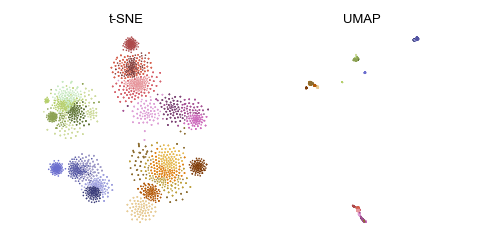

In [23]:
# Compute tSNE and UMAP

%time Z_tsne = TSNE(metric="precomputed").fit(D)
print("")
%time Z_umap = UMAP(metric="precomputed").fit_transform(D)

# Evaluate embeddings

rps, rss, sds, tas = dist_corrs(D, [Z_tsne, Z_umap], precomputed=True)
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z_tsne, Z_umap])
print("kNN acc:", knn)
print("lin acc:", lin)

# Plot

fig, axs = plt.subplots(ncols=2, figsize=(3.5, 1.7), layout="constrained")
titles = ["t-SNE", "UMAP"]

for i, Z in enumerate([Z_tsne, Z_umap]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=3, ec="none", c=y, rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])

Epoch  10, stress-1 0.410, time 0.0 s
Epoch  20, stress-1 0.416, time 0.0 s
Epoch  30, stress-1 0.413, time 0.0 s
Epoch  40, stress-1 0.412, time 0.0 s
Epoch  50, stress-1 0.413, time 0.0 s
Epoch  60, stress-1 0.410, time 0.0 s
Epoch  70, stress-1 0.410, time 0.0 s
Epoch  80, stress-1 0.411, time 0.0 s
Epoch  90, stress-1 0.410, time 0.0 s
Epoch 100, stress-1 0.409, time 0.0 s
Epoch 110, stress-1 0.409, time 0.0 s
Epoch 120, stress-1 0.409, time 0.1 s
Epoch 130, stress-1 0.408, time 0.1 s
Epoch 140, stress-1 0.409, time 0.1 s
Epoch 150, stress-1 0.408, time 0.0 s
Epoch 160, stress-1 0.408, time 0.0 s
Epoch 170, stress-1 0.407, time 0.1 s
Epoch 180, stress-1 0.408, time 0.0 s
Epoch 190, stress-1 0.407, time 0.0 s
Epoch 200, stress-1 0.408, time 0.0 s
CPU times: user 1min 32s, sys: 240 ms, total: 1min 33s
Wall time: 17.9 s
Stress-1 averaged over the last 5 epochs: 0.408


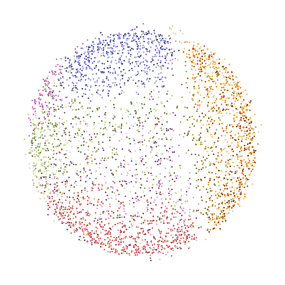

In [311]:
# Compute embeddings using SGD

%time Z, stresses = stochasticMDS(D, precomputed_distances=True)

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=3, ec="none", c=y, rasterized=True)
plt.axis("off");

print(f"Stress-1 averaged over the last 5 epochs: {stresses[-5:].mean():.3}") # 0.408

In [312]:
# Compute Stress-1 without batches

s = stress1(D, Z, non_metric=False, normalize_dist="mean_square_offdiag", precomputed=True, adjust=True)
print(f"Full stress-1: {s:.3}")

Full stress-1: 0.407


Epoch  10, stress-1 0.217, time 0.1 s
Epoch  20, stress-1 0.154, time 0.1 s
Epoch  30, stress-1 0.146, time 0.1 s
Epoch  40, stress-1 0.157, time 0.1 s
Epoch  50, stress-1 0.139, time 0.1 s
Epoch  60, stress-1 0.163, time 0.1 s
Epoch  70, stress-1 0.178, time 0.1 s
Epoch  80, stress-1 0.141, time 0.1 s
Epoch  90, stress-1 0.138, time 0.1 s
Epoch 100, stress-1 0.142, time 0.1 s
Epoch 110, stress-1 0.153, time 0.1 s
Epoch 120, stress-1 0.148, time 0.1 s
Epoch 130, stress-1 0.132, time 0.1 s
Epoch 140, stress-1 0.134, time 0.1 s
Epoch 150, stress-1 0.133, time 0.1 s
Epoch 160, stress-1 0.133, time 0.1 s
Epoch 170, stress-1 0.130, time 0.1 s
Epoch 180, stress-1 0.131, time 0.1 s
Epoch 190, stress-1 0.131, time 0.1 s
Epoch 200, stress-1 0.131, time 0.1 s
CPU times: user 1min 56s, sys: 334 ms, total: 1min 57s
Wall time: 23.5 s
Stress-1 averaged over the last 5 epochs: 0.141


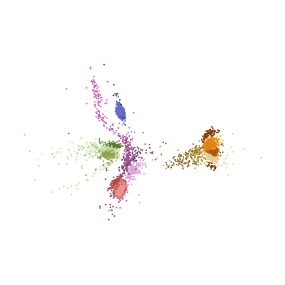

In [313]:
# Compute embeddings using SGD

%time Z, stresses = stochasticMDS(D, precomputed_distances=True, non_metric=True)

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=3, ec="none", c=y, rasterized=True)
plt.axis("off");

# print(f"Stress-1 averaged over the last 5 epochs: {stresses[-1]:.3}") # 0.132

In [315]:
# Compute Stress-1 without batches

s = stress1(D, Z, non_metric=True, normalize_dist="mean_square_offdiag", precomputed=True, adjust=True)
print(f"Full stress-1: {s:.3}")

Full stress-1: 0.127


## Tasic dataset

In [316]:
# Load data

X = np.load('tasic-data/tasic-pca50.npy')
y = np.load('tasic-data/tasic-colors.npy')

print(X.shape)

(23822, 50)


In [324]:
%time Z3, loss = stochasticMDS(X, non_metric=True, n_epochs=10, seed=2)  

Epoch   1, stress-1 0.196, time 2.5 s
Epoch   2, stress-1 0.165, time 2.8 s
Epoch   3, stress-1 0.143, time 2.9 s
Epoch   4, stress-1 0.132, time 2.9 s
Epoch   5, stress-1 0.124, time 2.9 s
Epoch   6, stress-1 0.119, time 2.9 s
Epoch   7, stress-1 0.116, time 2.9 s
Epoch   8, stress-1 0.115, time 2.9 s
Epoch   9, stress-1 0.114, time 2.9 s
Epoch  10, stress-1 0.122, time 2.9 s
CPU times: user 55.5 s, sys: 78.4 ms, total: 55.6 s
Wall time: 28.6 s


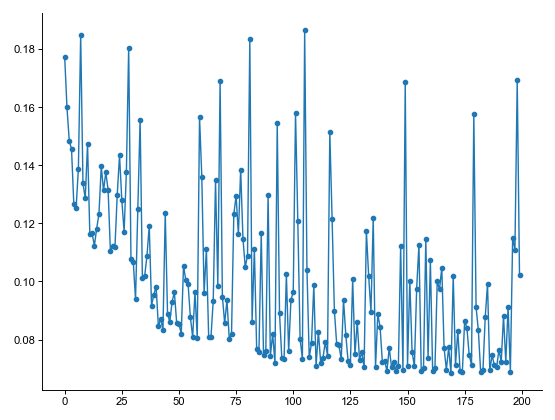

In [320]:
plt.figure(figsize=(4, 3))
plt.plot(loss, '.-')

In [193]:
%time Z22, loss = stochasticMDS(X, n_epochs=500, non_metric=True)  

Epoch  10, loss 0.128, time 3.1 s
Epoch  20, loss 0.119, time 3.1 s
Epoch  30, loss 0.109, time 3.1 s
Epoch  40, loss 0.104, time 3.1 s
Epoch  50, loss 0.103, time 3.1 s
Epoch  60, loss 0.119, time 3.1 s
Epoch  70, loss 0.088, time 3.1 s
Epoch  80, loss 0.112, time 3.1 s
Epoch  90, loss 0.133, time 3.1 s
Epoch 100, loss 0.098, time 3.1 s
Epoch 110, loss 0.112, time 3.1 s
Epoch 120, loss 0.077, time 3.1 s
Epoch 130, loss 0.092, time 3.0 s
Epoch 140, loss 0.116, time 3.0 s
Epoch 150, loss 0.233, time 3.1 s
Epoch 160, loss 0.071, time 3.0 s
Epoch 170, loss 0.070, time 3.1 s
Epoch 180, loss 0.189, time 3.1 s
Epoch 190, loss 0.067, time 3.1 s
Epoch 200, loss 0.284, time 3.0 s
Epoch 210, loss 0.128, time 3.0 s
Epoch 220, loss 0.077, time 3.0 s
Epoch 230, loss 0.226, time 3.0 s
Epoch 240, loss 0.122, time 3.1 s
Epoch 250, loss 0.082, time 3.2 s
Epoch 260, loss 0.066, time 3.0 s
Epoch 270, loss 0.094, time 3.1 s
Epoch 280, loss 0.078, time 3.1 s
Epoch 290, loss 0.157, time 3.1 s
Epoch 300, los

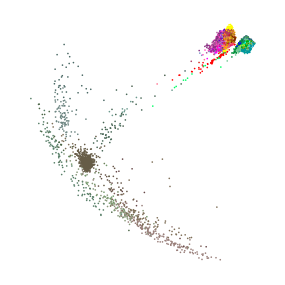

In [321]:
plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z2[:, 0], Z2[:, 1], s=3, ec="none", c=y, rasterized=True)
plt.axis("off");

In [30]:
# Compute embeddings using SGD

%time Z1 = PCA(n_components=2).fit_transform(X)
print("")

%time Z2, loss = stochasticMDS(X)  # loss = 0.247
print(f"MMDS stress-1: {loss:.3f}\n")

%time Z3, loss = stochasticMDS(X, n_epochs=500, non_metric=True) # loss = 0.076
print(f"NMDS stress-1: {loss:.3f}")

# This goes down to 0.076 in some epochs, and with n_epochs=200 it only goes 
# down to 0.083, and visually the concentric circle does not form so clearly

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z1, Z2, Z3])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z1, Z2, Z3])
print("kNN acc:", knn)
print("lin acc:", lin)

CPU times: user 37 ms, sys: 3.68 ms, total: 40.7 ms
Wall time: 14.4 ms

Epoch  10, loss 0.260, time 0.9 s
Epoch  20, loss 0.255, time 0.9 s
Epoch  30, loss 0.255, time 0.9 s
Epoch  40, loss 0.253, time 0.9 s
Epoch  50, loss 0.254, time 0.9 s
Epoch  60, loss 0.252, time 0.9 s
Epoch  70, loss 0.252, time 0.9 s
Epoch  80, loss 0.250, time 0.9 s
Epoch  90, loss 0.250, time 1.7 s
Epoch 100, loss 0.249, time 1.1 s
Epoch 110, loss 0.248, time 1.0 s
Epoch 120, loss 0.248, time 1.0 s
Epoch 130, loss 0.248, time 1.0 s
Epoch 140, loss 0.248, time 1.3 s
Epoch 150, loss 0.248, time 0.9 s
Epoch 160, loss 0.247, time 1.0 s
Epoch 170, loss 0.247, time 1.0 s
Epoch 180, loss 0.247, time 0.9 s
Epoch 190, loss 0.248, time 1.1 s
Epoch 200, loss 0.247, time 1.1 s
CPU times: user 10min 39s, sys: 732 ms, total: 10min 40s
Wall time: 3min 21s
MMDS stress-1: 0.247

Epoch  10, loss 0.134, time 3.1 s
Epoch  20, loss 0.121, time 3.4 s
Epoch  30, loss 0.125, time 3.2 s
Epoch  40, loss 0.112, time 3.3 s
Epoch  50, lo

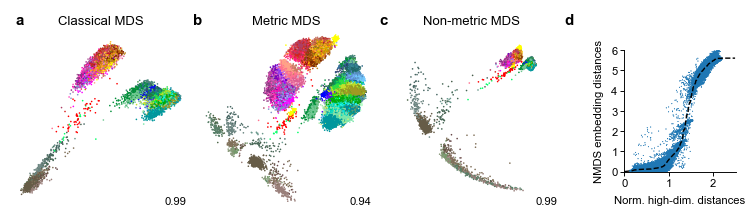

In [31]:
# Make a figure

titles = ["Classical MDS", "Metric MDS", "Non-metric MDS"]

fig, axs = plt.subplots(ncols=4, figsize=(5.5, 1.5), layout="constrained")

for i, Z in enumerate([Z1, Z2, Z3]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=3, ec="none", c=y, rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])
    axs[i].text(.99, .01, f"{tas[i]:.2f}", ha="right", transform=axs[i].transAxes, fontsize=6)

# NMDS Shepard diagram

axs[3].set_visible(False)
axs[3] = plt.axes([.83, .2, .15, .6])

ind = np.random.default_rng(seed=42).choice(X.shape[0], size=500, replace=False)
d1 = pairwise_distances(X[ind, :])
d2 = pairwise_distances(Z[ind, :])
d1 /= d1.mean()

ir = IsotonicRegression(out_of_bounds="clip")
ir.fit(d1.ravel(), d2.ravel())

axs[3].scatter(d1.flatten(), d2.flatten(), s=1, ec='none', rasterized=True)
axs[3].set_xlabel("Norm. high-dim. distances")
axs[3].set_ylabel("NMDS embedding distances")

xgrid = np.arange(0, 2.5, .01)
yhat = ir.transform(xgrid.reshape(-1, 1))
axs[3].plot(xgrid, yhat, 'k--')
axs[3].set_xlim([0, 2.5])
axs[3].set_ylim([0, 6])
axs[3].set_yticks([0, 1, 2, 3, 4, 5, 6])
axs[3].spines[["right", "top"]].set_visible(False)

fig.text(.01, .93, "a", fontweight="bold", fontsize=8)
fig.text(.25, .93, "b", fontweight="bold", fontsize=8)
fig.text(.50, .93, "c", fontweight="bold", fontsize=8)
fig.text(.75, .93, "d", fontweight="bold", fontsize=8)

fig.savefig("figures/tasic.png", dpi=300)
fig.savefig("figures/tasic.pdf", dpi=300)

CPU times: user 1min 34s, sys: 77.4 ms, total: 1min 34s
Wall time: 1min 33s



/home/dmitry/anaconda3/envs/nmds/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


CPU times: user 2min 8s, sys: 2.04 s, total: 2min 10s
Wall time: 20.5 s

Pearson: [0.45990679 0.54069283]
Spearman: [0.55038188 0.57567792]
Sigma-distortion: [0.19035439 0.21543203]
Triplet: [0.7816 0.786 ]
kNN acc: [0.9076794  0.89844734]
lin acc: [0.4817457  0.58203945]


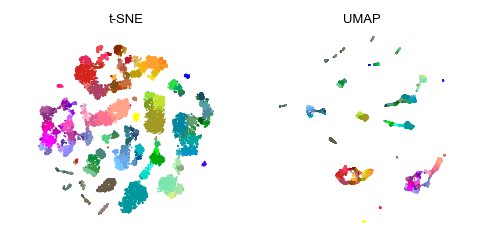

In [32]:
# Compute tSNE and UMAP

%time Z_tsne = TSNE().fit(X)
print("")
%time Z_umap = UMAP().fit_transform(X)

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z_tsne, Z_umap])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z_tsne, Z_umap])
print("kNN acc:", knn)
print("lin acc:", lin)

# Plot

fig, axs = plt.subplots(ncols=2, figsize=(3.5, 1.7), layout="constrained")
titles = ["t-SNE", "UMAP"]

for i, Z in enumerate([Z_tsne, Z_umap]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=3, ec="none", c=y, rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])

In [14]:
ann = np.load('tasic-data/tasic-ttypes.npy')

exc_types = [
    t for t in np.unique(ann) if t[:3] in ['L2/', 'L4 ', 'L5 ', 'L6 ', 'L6b']
]

inh_types = [
    t for t in np.unique(ann) if t[:4] in ['Lamp', 'Pval', 'Serp', 'Sncg', 'Sst ', 'Vip ']
]

non_types = [
    t for t in np.unique(ann) if t[:4] in [
        'Astr', 'Endo', 'Micr', 'OPC ', 'Olig', 'SMC ', 'PVM ', 'Peri', 'VLMC'
    ]
]

[t for t in np.unique(ann) if t not in exc_types + inh_types + non_types]

['CR Lhx5', 'Meis2 Adamts19']

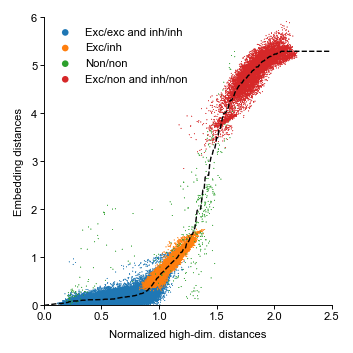

In [36]:
def tasic_distance_plot(Z, add_isotonic_line=False):
    ind = np.random.default_rng(seed=42).choice(X.shape[0], size=500, replace=False)

    d1 = pairwise_distances(X[ind, :])
    d2 = pairwise_distances(Z[ind, :])
    d1 /= d1.mean()

    plt.figure(figsize=(2.5, 2.5), layout="constrained")
    plt.xlabel('Normalized high-dim. distances')
    plt.ylabel('Embedding distances');

    classes = np.zeros(len(ind)).astype(int) - 10
    classes[np.isin(ann[ind], exc_types)] = 0
    classes[np.isin(ann[ind], inh_types)] = 1
    classes[np.isin(ann[ind], non_types)] = 3
    d_classes = np.abs(classes + classes[:, np.newaxis])
    
    dd = np.zeros(d_classes.shape).astype(int) - 10
    dd[np.isin(d_classes, [0, 2])] = 0
    dd[d_classes == 1] = 1
    dd[d_classes == 6] = 2
    dd[np.isin(d_classes, [3, 4])] = 3
    
    labels = ["Exc/exc and inh/inh", "Exc/inh", 'Non/non', "Exc/non and inh/non"]

    for i, label in enumerate(labels):
        plt.scatter(
            d1.flatten()[dd.flatten() == i],
            d2.flatten()[dd.flatten() == i],
            s=1,
            ec='none',
            label=label,
            rasterized=True,
        )

    plt.xlim([0, 2.5])
    plt.ylim([0, 6])
        
    lgnd = plt.legend()
    for handle in lgnd.legendHandles:
        handle.set_sizes([50])
        
    if add_isotonic_line:
        ir = IsotonicRegression(out_of_bounds="clip")
        ir.fit(d1.ravel(), d2.ravel())
        
        xgrid = np.arange(0, 2.5, .01)
        yhat = ir.transform(xgrid.reshape(-1, 1))
        plt.plot(xgrid, yhat, 'k--');

tasic_distance_plot(Z3, add_isotonic_line=True)

plt.savefig("figures/tasic-shepard.pdf")
plt.savefig("figures/tasic-shepard.png", dpi=300)

In [77]:
%%time

bs = [100, 300, 1000, 3000]
lr = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]

losses = np.zeros((len(bs), len(lr)))
for i, b in enumerate(bs):
    for j, l in enumerate(lr):
        _, loss = stochasticMDS(X, batch_size=b, lr=l, verbose=True)
        losses[i, j] = loss
        print("")

Epoch  10, loss 0.119, time 0.3 s
Epoch  20, loss 0.085, time 0.4 s
Epoch  30, loss 0.075, time 0.3 s
Epoch  40, loss 0.072, time 0.4 s
Epoch  50, loss 0.070, time 0.5 s
Epoch  60, loss 0.070, time 0.4 s
Epoch  70, loss 0.069, time 0.4 s
Epoch  80, loss 0.068, time 0.5 s
Epoch  90, loss 0.068, time 0.5 s
Epoch 100, loss 0.067, time 0.9 s
Epoch 110, loss 0.068, time 0.5 s
Epoch 120, loss 0.068, time 0.7 s
Epoch 130, loss 0.067, time 0.6 s
Epoch 140, loss 0.067, time 0.5 s
Epoch 150, loss 0.067, time 0.6 s
Epoch 160, loss 0.067, time 0.6 s
Epoch 170, loss 0.067, time 0.6 s
Epoch 180, loss 0.066, time 0.7 s
Epoch 190, loss 0.067, time 0.5 s
Epoch 200, loss 0.066, time 0.5 s

Epoch  10, loss 0.079, time 0.5 s
Epoch  20, loss 0.072, time 0.5 s
Epoch  30, loss 0.070, time 0.6 s
Epoch  40, loss 0.069, time 0.5 s
Epoch  50, loss 0.068, time 0.5 s
Epoch  60, loss 0.068, time 0.5 s
Epoch  70, loss 0.067, time 0.5 s
Epoch  80, loss 0.066, time 0.5 s
Epoch  90, loss 0.066, time 0.6 s
Epoch 100, lo

Epoch  20, loss 0.123, time 1.5 s
Epoch  30, loss 0.105, time 1.4 s
Epoch  40, loss 0.093, time 1.3 s
Epoch  50, loss 0.086, time 1.3 s
Epoch  60, loss 0.081, time 1.3 s
Epoch  70, loss 0.078, time 1.3 s
Epoch  80, loss 0.076, time 1.4 s
Epoch  90, loss 0.074, time 1.3 s
Epoch 100, loss 0.073, time 1.4 s
Epoch 110, loss 0.072, time 1.3 s
Epoch 120, loss 0.071, time 1.3 s
Epoch 130, loss 0.071, time 1.3 s
Epoch 140, loss 0.070, time 1.3 s
Epoch 150, loss 0.070, time 1.3 s
Epoch 160, loss 0.070, time 1.3 s
Epoch 170, loss 0.069, time 1.4 s
Epoch 180, loss 0.070, time 1.3 s
Epoch 190, loss 0.069, time 1.4 s
Epoch 200, loss 0.069, time 1.4 s

Epoch  10, loss 0.107, time 1.3 s
Epoch  20, loss 0.081, time 1.3 s
Epoch  30, loss 0.073, time 1.4 s
Epoch  40, loss 0.070, time 1.3 s
Epoch  50, loss 0.068, time 1.3 s
Epoch  60, loss 0.067, time 1.4 s
Epoch  70, loss 0.067, time 1.4 s
Epoch  80, loss 0.066, time 1.4 s
Epoch  90, loss 0.066, time 1.4 s
Epoch 100, loss 0.066, time 1.3 s
Epoch 110, lo

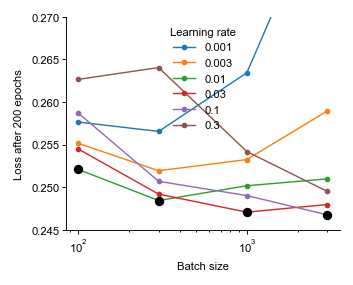

In [37]:
bs = [100, 300, 1000, 3000]
lr = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]

losses = np.array(
    [[0.0663873 , 0.06510564, 0.06355584, 0.0647683 , 0.06693342,
        0.0689907 ],
       [0.06582094, 0.06347827, 0.06172996, 0.06210217, 0.06285295,
        0.06971835],
       [0.06939651, 0.06413994, 0.0625941 , 0.06105488, 0.06201865,
        0.06461662],
       [0.08135978, 0.06705816, 0.06299702, 0.06149812, 0.06089953,
        0.06226252]]
)

losses = np.sqrt(losses)

plt.figure(figsize=(2.5, 2), layout="constrained")
plt.plot(bs, losses, '.-')
plt.xscale('log')
plt.legend(lr, title="Learning rate", fontsize=6)
plt.xlabel('Batch size')
plt.ylabel('Loss after 200 epochs')

plt.plot(bs, np.min(losses, axis=1), 'ko')
plt.ylim([0.245, 0.27])

# batch size 100, 300   -- lr 0.01
# batch size 1000       -- lr 0.03
# batch size 3000       -- lr 0.1

plt.savefig("figures/sgd-params-tasic.pdf")
plt.savefig("figures/sgd-params-tasic.png", dpi=300)

## Digits dataset

In [33]:
# Load data

X, y = load_digits(return_X_y=True)
print(X.shape)

(1797, 64)


In [34]:
# Compute embeddings using sklearn

cmds = ClassicalMDS()
%time Z1 = cmds.fit_transform(X)
print("")

mmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", verbose=1)
%time Z2 = mmds.fit_transform(X)
stress1_rescaled = np.sqrt(mmds.stress_**2 / (1 + mmds.stress_**2))
print(f"MMDS stress-1: {stress1_rescaled:.3f}\n")

nmds = MDS(normalized_stress=True, n_init=1, init="classical_mds", metric_mds=False, verbose=1)
%time Z3 = nmds.fit_transform(X)
print(f"NMDS stress-1: {nmds.stress_:.3f}")

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z1, Z2, Z3])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z1, Z2, Z3])
print("kNN acc:", knn)
print("lin acc:", lin)

CPU times: user 7.12 s, sys: 12.8 ms, total: 7.13 s
Wall time: 977 ms

Convergence criterion reached (iteration 176).
CPU times: user 1min 40s, sys: 237 ms, total: 1min 40s
Wall time: 13.7 s
MMDS stress-1: 0.328

Convergence criterion reached (iteration 148).
CPU times: user 5min 8s, sys: 2.39 s, total: 5min 11s
Wall time: 2min 30s
NMDS stress-1: 0.292

Pearson: [0.56713989 0.72114504 0.73522876]
Spearman: [0.55991375 0.72749802 0.75031752]
Sigma-distortion: [0.18177883 0.15251832 0.15339571]
Triplet: [0.7972 0.8436 0.8578]
kNN acc: [0.69444444 0.75       0.71111111]
lin acc: [0.65555556 0.69444444 0.70555556]


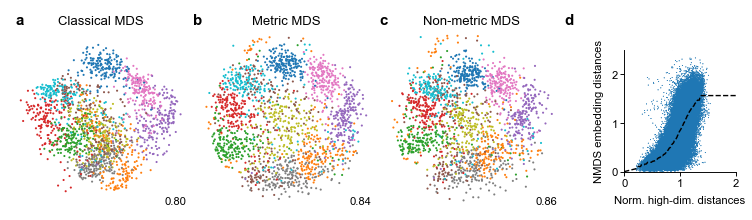

In [35]:
# Make a figure

titles = ["Classical MDS", "Metric MDS", "Non-metric MDS"]

fig, axs = plt.subplots(ncols=4, figsize=(5.5, 1.5), layout="constrained")

for i, Z in enumerate([Z1, Z2, Z3]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=5, ec="none", c=y, cmap='tab10', rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])
    axs[i].text(.99, .01, f"{tas[i]:.2f}", ha="right", transform=axs[i].transAxes)

# NMDS Shepard diagram

axs[3].set_visible(False)
axs[3] = plt.axes([.83, .2, .15, .6])

ind = np.random.default_rng(seed=42).choice(X.shape[0], size=500, replace=False)
d1 = pairwise_distances(X[ind, :])
d2 = pairwise_distances(Z[ind, :])
d1 /= d1.mean()

ir = IsotonicRegression(out_of_bounds="clip")
ir.fit(d1.ravel(), d2.ravel())

axs[3].scatter(d1.flatten(), d2.flatten(), s=1, ec='none', rasterized=True)
axs[3].set_xlabel("Norm. high-dim. distances")
axs[3].set_ylabel("NMDS embedding distances")

xgrid = np.arange(0, 2.5, .01)
yhat = ir.transform(xgrid.reshape(-1, 1))
axs[3].plot(xgrid, yhat, 'k--')
axs[3].set_xlim([0, 2])
axs[3].set_ylim([0, 2.5])
axs[3].set_yticks([0, 1, 2])
axs[3].spines[["right", "top"]].set_visible(False)

fig.text(.01, .93, "a", fontweight="bold", fontsize=8)
fig.text(.25, .93, "b", fontweight="bold", fontsize=8)
fig.text(.50, .93, "c", fontweight="bold", fontsize=8)
fig.text(.75, .93, "d", fontweight="bold", fontsize=8)

fig.savefig("figures/digits.png", dpi=300)
fig.savefig("figures/digits.pdf", dpi=300)

CPU times: user 9.43 s, sys: 5.61 ms, total: 9.43 s
Wall time: 8.71 s

CPU times: user 20.5 s, sys: 504 ms, total: 21 s
Wall time: 5.21 s

Pearson: [0.54521327 0.38003919]
Spearman: [0.50179595 0.37705522]
Sigma-distortion: [0.21025908 0.41301063]
Triplet: [0.741  0.6794]
kNN acc: [0.98333333 0.99444444]
lin acc: [0.91111111 0.92777778]


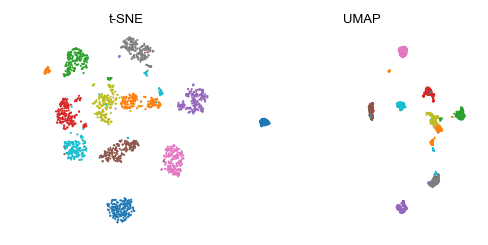

In [36]:
# Compute tSNE and UMAP

%time Z_tsne = TSNE().fit(X)
print("")
%time Z_umap = UMAP().fit_transform(X)

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z_tsne, Z_umap])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z_tsne, Z_umap])
print("kNN acc:", knn)
print("lin acc:", lin)

# Plot

fig, axs = plt.subplots(ncols=2, figsize=(3.5, 1.7), layout="constrained")
titles = ["t-SNE", "UMAP"]

for i, Z in enumerate([Z_tsne, Z_umap]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=5, ec="none", c=y, cmap='tab10', rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])

Epoch  10, loss 0.337, time 0.0 s
Epoch  20, loss 0.334, time 0.0 s
Epoch  30, loss 0.333, time 0.0 s
Epoch  40, loss 0.335, time 0.0 s
Epoch  50, loss 0.334, time 0.0 s
Epoch  60, loss 0.334, time 0.0 s
Epoch  70, loss 0.331, time 0.0 s
Epoch  80, loss 0.331, time 0.0 s
Epoch  90, loss 0.333, time 0.0 s
Epoch 100, loss 0.330, time 0.0 s
Epoch 110, loss 0.331, time 0.0 s
Epoch 120, loss 0.331, time 0.0 s
Epoch 130, loss 0.330, time 0.0 s
Epoch 140, loss 0.329, time 0.0 s
Epoch 150, loss 0.329, time 0.0 s
Epoch 160, loss 0.329, time 0.0 s
Epoch 170, loss 0.329, time 0.0 s
Epoch 180, loss 0.328, time 0.0 s
Epoch 190, loss 0.330, time 0.0 s
Epoch 200, loss 0.328, time 0.0 s
CPU times: user 27.8 s, sys: 31.3 ms, total: 27.9 s
Wall time: 6.85 s


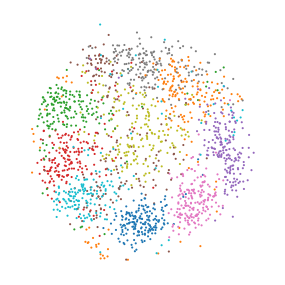

In [38]:
# Compute embeddings using SGD

%time Z, loss = stochasticMDS(X) # loss = 0.329

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=5, ec="none", c=y, cmap='tab10', rasterized=True)
plt.axis("off");

Epoch  10, loss 0.299, time 0.0 s
Epoch  20, loss 0.289, time 0.0 s
Epoch  30, loss 0.290, time 0.1 s
Epoch  40, loss 0.290, time 0.1 s
Epoch  50, loss 0.289, time 0.0 s
Epoch  60, loss 0.290, time 0.0 s
Epoch  70, loss 0.289, time 0.0 s
Epoch  80, loss 0.285, time 0.0 s
Epoch  90, loss 0.286, time 0.0 s
Epoch 100, loss 0.285, time 0.1 s
Epoch 110, loss 0.284, time 0.1 s
Epoch 120, loss 0.285, time 0.1 s
Epoch 130, loss 0.283, time 0.1 s
Epoch 140, loss 0.281, time 0.1 s
Epoch 150, loss 0.285, time 0.1 s
Epoch 160, loss 0.283, time 0.1 s
Epoch 170, loss 0.285, time 0.1 s
Epoch 180, loss 0.283, time 0.1 s
Epoch 190, loss 0.283, time 0.1 s
Epoch 200, loss 0.284, time 0.1 s
CPU times: user 47 s, sys: 33.4 ms, total: 47 s
Wall time: 11.7 s


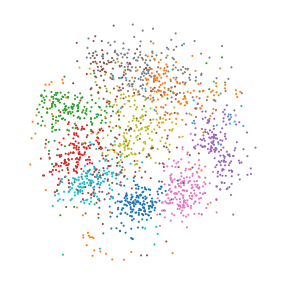

In [39]:
# Compute embeddings using SGD

%time Z, loss = stochasticMDS(X, non_metric=True) # loss = 0.283

plt.figure(figsize=(2, 2), layout="constrained")
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=5, ec="none", c=y, cmap='tab10', rasterized=True)
plt.axis("off");

## MNIST

In [37]:
# Load data

from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

print(X.shape)

(70000, 784)


In [16]:
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=-10, print_every_epoch=10)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=-5,  print_every_epoch=10)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=0,   print_every_epoch=10)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=10,  print_every_epoch=10)
%time Z, loss = stochasticMDS(X, non_metric=True, isotonic_fit_how_often=1,   print_every_epoch=10)

Epoch  10, loss 0.321, time 31.6 s
Epoch  20, loss 0.297, time 32.8 s
CPU times: user 14min 49s, sys: 536 ms, total: 14min 49s
Wall time: 11min 32s
Epoch  10, loss 0.306, time 30.8 s
Epoch  20, loss 0.294, time 31.0 s
CPU times: user 13min 53s, sys: 448 ms, total: 13min 54s
Wall time: 10min 42s
Epoch  10, loss 0.298, time 31.2 s
Epoch  20, loss 0.293, time 30.9 s
CPU times: user 13min 32s, sys: 260 ms, total: 13min 32s
Wall time: 10min 22s
Epoch  10, loss 0.299, time 32.7 s
Epoch  20, loss 0.293, time 33.0 s
CPU times: user 14min 3s, sys: 212 ms, total: 14min 3s
Wall time: 10min 57s
Epoch  10, loss 0.298, time 52.7 s
Epoch  20, loss 0.292, time 52.8 s
CPU times: user 20min 43s, sys: 192 ms, total: 20min 43s
Wall time: 17min 38s


In [38]:
# Compute embeddings using SGD

%time Z1 = PCA(n_components=2).fit_transform(X)
print("")

%time Z2, loss = stochasticMDS(X)  # loss = 0.247
print(f"MMDS stress-1: {loss:.3f}\n")

%time Z3, loss = stochasticMDS(X, non_metric=True) # loss = 0.095
print(f"NMDS stress-1: {loss:.3f}")

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z1, Z2, Z3])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z1, Z2, Z3])
print("kNN acc:", knn)
print("lin acc:", lin)

CPU times: user 3.98 s, sys: 287 ms, total: 4.27 s
Wall time: 873 ms

Epoch   1, loss 0.444, time 24.6 s
Epoch   2, loss 0.391, time 30.9 s
Epoch   3, loss 0.375, time 36.2 s
Epoch   4, loss 0.370, time 40.2 s
Epoch   5, loss 0.367, time 27.2 s
Epoch   6, loss 0.365, time 26.6 s
Epoch   7, loss 0.365, time 30.2 s
Epoch   8, loss 0.365, time 32.4 s
Epoch   9, loss 0.364, time 26.8 s
Epoch  10, loss 0.362, time 26.3 s
Epoch  11, loss 0.361, time 27.9 s
Epoch  12, loss 0.360, time 26.9 s
Epoch  13, loss 0.360, time 26.7 s
Epoch  14, loss 0.360, time 28.6 s
Epoch  15, loss 0.359, time 26.2 s
Epoch  16, loss 0.359, time 24.9 s
Epoch  17, loss 0.359, time 24.9 s
Epoch  18, loss 0.359, time 24.5 s
Epoch  19, loss 0.359, time 26.0 s
Epoch  20, loss 0.359, time 26.1 s
CPU times: user 11min 34s, sys: 603 ms, total: 11min 35s
Wall time: 9min 25s
MMDS stress-1: 0.359

Epoch   1, loss 0.435, time 39.6 s
Epoch   2, loss 0.371, time 40.6 s
Epoch   3, loss 0.346, time 36.2 s
Epoch   4, loss 0.328, tim

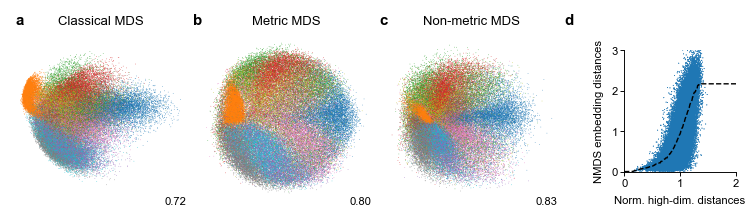

In [39]:
# Make a figure

titles = ["Classical MDS", "Metric MDS", "Non-metric MDS"]

fig, axs = plt.subplots(ncols=4, figsize=(5.5, 1.5), layout="constrained")

for i, Z in enumerate([Z1, Z2, Z3]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=.5, ec="none", c=y, cmap='tab10', rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])
    axs[i].text(.99, .01, f"{tas[i]:.2f}", ha="right", transform=axs[i].transAxes, fontsize=6)

    # if i == 1:
        # ind = np.random.default_rng(seed=42).choice(
        #     X.shape[0],
        #     size=500,
        #     replace=False
        # )
        # dists = pairwise_distances(X[ind, :])
        # mean_dist = np.mean(dists[dists > 0])
        # c = plt.Circle((0, 0), 1 * np.pi / 4, facecolor="none", edgecolor="k", linestyle='--', lw=.6, zorder=0)
        # axs[i].add_patch(c)

# NMDS Shepard diagram

axs[3].set_visible(False)
axs[3] = plt.axes([.83, .2, .15, .6])

ind = np.random.default_rng(seed=42).choice(X.shape[0], size=500, replace=False)
d1 = pairwise_distances(X[ind, :])
d2 = pairwise_distances(Z[ind, :])
d1 /= d1.mean()

ir = IsotonicRegression(out_of_bounds="clip")
ir.fit(d1.ravel(), d2.ravel())

axs[3].scatter(d1.flatten(), d2.flatten(), s=1, ec='none', rasterized=True)
axs[3].set_xlabel("Norm. high-dim. distances")
axs[3].set_ylabel("NMDS embedding distances")

xgrid = np.arange(0, 2.5, .01)
yhat = ir.transform(xgrid.reshape(-1, 1))
axs[3].plot(xgrid, yhat, 'k--')
axs[3].set_xlim([0, 2])
axs[3].set_ylim([0, 3])
axs[3].set_yticks([0, 1, 2, 3])
axs[3].spines[["right", "top"]].set_visible(False)

fig.text(.01, .93, "a", fontweight="bold", fontsize=8)
fig.text(.25, .93, "b", fontweight="bold", fontsize=8)
fig.text(.50, .93, "c", fontweight="bold", fontsize=8)
fig.text(.75, .93, "d", fontweight="bold", fontsize=8)

fig.savefig("figures/mnist.png", dpi=300)
fig.savefig("figures/mnist.pdf", dpi=300)

CPU times: user 7min 41s, sys: 339 ms, total: 7min 41s
Wall time: 7min 34s

CPU times: user 6min 46s, sys: 4.94 s, total: 6min 51s
Wall time: 1min 11s

Pearson: [0.39845289 0.36148901]
Spearman: [0.37799075 0.32390807]
Sigma-distortion: [0.21117231 0.2817677 ]
Triplet: [0.663  0.6368]
kNN acc: [0.96685714 0.95885714]
lin acc: [0.93314286 0.94957143]


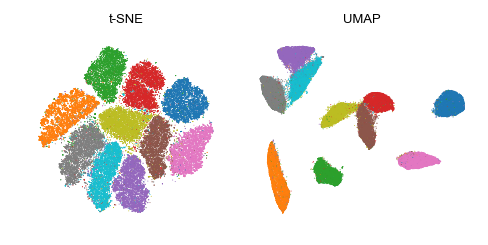

In [40]:
# Compute tSNE and UMAP

%time Z_tsne = TSNE().fit(X)
print("")
%time Z_umap = UMAP().fit_transform(X)

# Evaluate embeddings

print("")

rps, rss, sds, tas = dist_corrs(X, [Z_tsne, Z_umap])
print("Pearson:", rps)
print("Spearman:", rss)
print("Sigma-distortion:", sds)
print("Triplet:", tas)

knn, lin = classif_eval(y, [Z_tsne, Z_umap])
print("kNN acc:", knn)
print("lin acc:", lin)
# Plot

fig, axs = plt.subplots(ncols=2, figsize=(3.5, 1.7), layout="constrained")
titles = ["t-SNE", "UMAP"]

for i, Z in enumerate([Z_tsne, Z_umap]):
    axs[i].set_aspect("equal", adjustable="datalim")
    axs[i].scatter(Z[:, 0], Z[:, 1], s=1, ec="none", c=y, cmap='tab10', rasterized=True)
    axs[i].set_axis_off()
    axs[i].set_title(titles[i])

In [49]:
%%time

bs = [100, 300, 1000, 3000]
lr = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]

losses = np.zeros((len(bs), len(lr)))
for i, b in enumerate(bs):
    for j, l in enumerate(lr):
#         print(".", end="")
        _, loss = stochasticMDS(X, batch_size=b, lr=l, verbose=True)
        losses[i, j] = loss
        print("")

Epoch   1, loss 0.203, time 4.9 s
Epoch   2, loss 0.189, time 5.2 s
Epoch   3, loss 0.177, time 5.5 s
Epoch   4, loss 0.168, time 5.9 s
Epoch   5, loss 0.161, time 6.7 s
Epoch   6, loss 0.156, time 6.9 s
Epoch   7, loss 0.152, time 7.0 s
Epoch   8, loss 0.149, time 7.0 s
Epoch   9, loss 0.147, time 7.0 s
Epoch  10, loss 0.145, time 7.0 s
Epoch  11, loss 0.144, time 7.0 s
Epoch  12, loss 0.143, time 7.1 s
Epoch  13, loss 0.143, time 6.9 s
Epoch  14, loss 0.142, time 7.0 s
Epoch  15, loss 0.142, time 6.9 s
Epoch  16, loss 0.141, time 7.0 s
Epoch  17, loss 0.141, time 6.9 s
Epoch  18, loss 0.141, time 6.9 s
Epoch  19, loss 0.141, time 7.1 s
Epoch  20, loss 0.141, time 6.9 s

Epoch   1, loss 0.203, time 7.0 s
Epoch   2, loss 0.169, time 6.9 s
Epoch   3, loss 0.153, time 6.9 s
Epoch   4, loss 0.146, time 6.9 s
Epoch   5, loss 0.142, time 6.8 s
Epoch   6, loss 0.140, time 6.9 s
Epoch   7, loss 0.139, time 7.0 s
Epoch   8, loss 0.137, time 6.9 s
Epoch   9, loss 0.136, time 7.0 s
Epoch  10, lo

Epoch  19, loss 0.256, time 13.4 s
Epoch  20, loss 0.219, time 13.8 s

Epoch   1, loss 0.197, time 38.4 s
Epoch   2, loss 0.192, time 38.1 s
Epoch   3, loss 0.186, time 38.3 s
Epoch   4, loss 0.182, time 38.5 s
Epoch   5, loss 0.177, time 38.1 s
Epoch   6, loss 0.174, time 38.3 s
Epoch   7, loss 0.171, time 38.3 s
Epoch   8, loss 0.168, time 38.0 s
Epoch   9, loss 0.166, time 38.3 s
Epoch  10, loss 0.164, time 38.3 s
Epoch  11, loss 0.163, time 38.1 s
Epoch  12, loss 0.161, time 38.4 s
Epoch  13, loss 0.160, time 38.1 s
Epoch  14, loss 0.160, time 38.2 s
Epoch  15, loss 0.159, time 38.2 s
Epoch  16, loss 0.159, time 38.2 s
Epoch  17, loss 0.158, time 38.3 s
Epoch  18, loss 0.158, time 38.4 s
Epoch  19, loss 0.158, time 38.1 s
Epoch  20, loss 0.158, time 38.3 s

Epoch   1, loss 0.197, time 38.1 s
Epoch   2, loss 0.182, time 38.2 s
Epoch   3, loss 0.171, time 38.6 s
Epoch   4, loss 0.162, time 38.3 s
Epoch   5, loss 0.157, time 38.9 s
Epoch   6, loss 0.152, time 38.8 s
Epoch   7, loss 0.

Epoch  10, loss 0.181, time 105.0 s
Epoch  11, loss 0.242, time 105.1 s
Epoch  12, loss 0.211, time 105.0 s
Epoch  13, loss 0.395, time 104.9 s
Epoch  14, loss 0.333, time 105.2 s
Epoch  15, loss 0.232, time 105.0 s
Epoch  16, loss 0.164, time 105.1 s
Epoch  17, loss 0.147, time 105.2 s
Epoch  18, loss 0.143, time 105.0 s
Epoch  19, loss 0.142, time 104.9 s
Epoch  20, loss 0.141, time 105.0 s



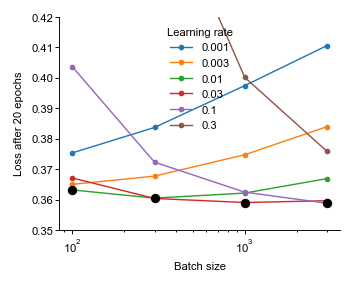

In [45]:
bs = [100, 300, 1000, 3000]
lr = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]

losses = np.array(
    [[0.14085095, 0.13320919, 0.13188436, 0.13475399, 0.16291423,
        0.20242522],
       [0.14719454, 0.13519147, 0.12993292, 0.12985621, 0.13858374,
        0.21924138],
       [0.15791675, 0.14040833, 0.13113213, 0.12889505, 0.13134885,
        0.16008258],
       [0.16853741, 0.14739493, 0.13459378, 0.12932111, 0.12871965,
        0.14123167]]
)

losses = np.sqrt(losses)

plt.figure(figsize=(2.5, 2), layout="constrained")
plt.plot(bs, losses, '.-')
plt.xscale('log')
plt.legend(lr, title="Learning rate")
plt.xlabel('Batch size')
plt.ylabel('Loss after 20 epochs')

plt.plot(bs, np.min(losses, axis=1), 'ko')
plt.ylim([0.35, 0.42])

# batch size 100        -- lr 0.01
# batch sizes 300, 1000 -- lr 0.03
# batch size 3000       -- lr 0.1
# For small batch sizes and large learning rates => very jumpy optimization

plt.savefig("figures/sgd-params-mnist.pdf")
plt.savefig("figures/sgd-params-mnist.png", dpi=300)